# Week 12 Bonus Lab — Streamflow in the Tucson basin

**HWRS 564a · Fall 2026 · Optional**

This is an optional lab. It uses the same `dataretrieval.waterdata` tools as the
Pinal water-level lab, but for streams instead of wells. You download 30 years
of daily streamflow at five USGS gages in the Tucson basin, from Sabino Creek in
the Santa Catalina Mountains down to the Santa Cruz River at Cortaro, and
compare how often each one flows, when it flows, and how much water reaches it.

## How to use this notebook

Run each cell with **Shift+Enter**. Cells marked  **`# YOUR TURN`**  have
something for you to write. Cells marked **`# CHECK`** verify your answer — if
they run without an error, you're right.

## Learning objectives

By the end of this notebook you can:

1. Download daily streamflow for several gages in one request with
   `dataretrieval.waterdata.get_daily`.
2. Find and remove duplicate days in a downloaded record.
3. Summarize a flow record by gage, by month, and by water year with `groupby`.
4. Convert mean streamflow to runoff depth, so gages with different drainage
   areas can be compared.
5. Describe what the records say about stream-channel recharge and about
   treated wastewater in the Santa Cruz River.

---

## Part 1 — The five gages

Water from the Santa Catalina and Rincon Mountains drains to the Rillito, which
joins the Santa Cruz River northwest of downtown Tucson. We use five gages along
that path:

| Gage | USGS ID | Where it is |
|---|---|---|
| Sabino Creek | 09484000 | Sabino Canyon, where the creek leaves the Santa Catalina Mountains |
| Tanque Verde Creek | 09484500 | Tanque Verde Creek at Tucson, below Sabino Creek |
| Rillito Creek | 09486055 | Rillito Creek at La Cholla Blvd, near where it joins the Santa Cruz |
| Santa Cruz at Tucson | 09482500 | Santa Cruz River at Congress Street, downtown |
| Santa Cruz at Cortaro | 09486500 | Santa Cruz River at Cortaro Road, below the Rillito |

Each gage's **drainage area** is the land area that drains to it, in square
miles. A gage downstream includes the drainage area of every gage upstream of
it. The areas and locations below come from the USGS site descriptions.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("../..")
CACHE = ROOT / "data" / "cache"

GAGES = pd.DataFrame({
    "site": ["USGS-09484000", "USGS-09484500", "USGS-09486055",
             "USGS-09482500", "USGS-09486500"],
    "name": ["Sabino Creek", "Tanque Verde Creek", "Rillito Creek",
             "Santa Cruz at Tucson", "Santa Cruz at Cortaro"],
    "drainage_area_mi2": [35.5, 219, 922, 2222, 3503],
    "lon": [-110.811, -110.841, -111.011, -110.982, -111.096],
    "lat": [32.315, 32.264, 32.303, 32.221, 32.351],
    "color": ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"],
})
GAGES

,site,name,drainage_area_mi2,lon,lat,color
0,USGS-09484000,Sabino Creek,35.5,-110.811,32.315,#2a78d6
1,USGS-09484500,Tanque Verde Creek,219.0,-110.841,32.264,#eb6834
2,USGS-09486055,Rillito Creek,922.0,-111.011,32.303,#1baf7a
3,USGS-09482500,Santa Cruz at Tucson,2222.0,-110.982,32.221,#eda100
4,USGS-09486500,Santa Cruz at Cortaro,3503.0,-111.096,32.351,#e87ba4


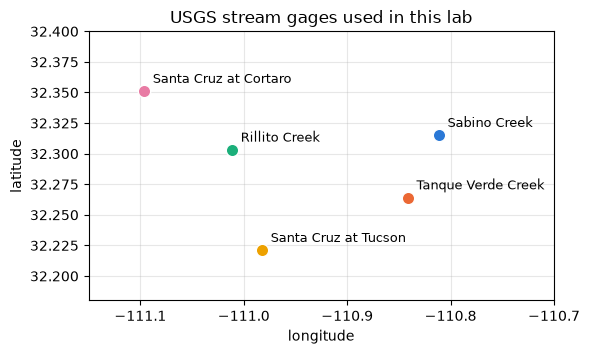

In [2]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for _, g in GAGES.iterrows():
    ax.scatter(g["lon"], g["lat"], s=80, color=g["color"], edgecolor="white", zorder=3)
    ax.annotate(g["name"], (g["lon"], g["lat"]), xytext=(6, 6),
                textcoords="offset points", fontsize=9)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title("USGS stream gages used in this lab")
ax.set_aspect(1 / np.cos(np.radians(32.3)))
ax.set_xlim(-111.15, -110.70)
ax.set_ylim(32.18, 32.40)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---

## Part 2 — Download the daily flows

`get_daily` returns one value per day: here, the **daily mean discharge**
(parameter code `00060`, statistic code `00003`), in cubic feet per second
(cfs). You can ask for several gages at once by passing a list of IDs.

We download water years 1996 through 2025. A **water year** runs from October 1
to September 30 and is named for the year it ends in, so water year 2025 is
October 1, 2024 to September 30, 2025. All five gages were running for that
whole period.

The download takes about 10 seconds.

In [3]:
from dataretrieval import waterdata

raw, md = waterdata.get_daily(
    monitoring_location_id=list(GAGES["site"]),
    parameter_code="00060",
    statistic_id="00003",
    time="1995-10-01/2025-09-30",
)
print("request:", md.url)
print(f"downloaded from the USGS: {len(raw):,} rows")

Geopandas not installed. Geometries will be flattened into pandas DataFrames.
Retrieving: daily · 2 pages · 59,604 rows
No API key detected — register for higher rate limits at https://api.waterdata.usgs.gov/signup/


request: https://api.waterdata.usgs.gov/ogcapi/v0/collections/daily/items?monitoring_location_id=USGS-09484000%2CUSGS-09484500%2CUSGS-09486055%2CUSGS-09482500%2CUSGS-09486500&parameter_code=00060&statistic_id=00003&time=1995-10-01%2F2025-09-30&limit=50000
downloaded from the USGS: 59,604 rows


Look at the columns, then keep the three we need: the gage ID, the date, and
the discharge.

In [4]:
print(list(raw.columns))
raw[["monitoring_location_id", "time", "value", "unit_of_measure", "approval_status"]].head()

['time_series_id', 'monitoring_location_id', 'parameter_code', 'statistic_id', 'time', 'value', 'unit_of_measure', 'approval_status', 'qualifier', 'last_modified', 'geometry', 'daily_id']


,monitoring_location_id,time,value,unit_of_measure,approval_status
0,USGS-09482500,1995-10-01,0.00,ft^3/s,Approved
1,USGS-09484000,1995-10-01,0.02,ft^3/s,Approved
2,USGS-09484500,1995-10-01,0.00,ft^3/s,Approved
3,USGS-09486055,1995-10-01,0.00,ft^3/s,Approved
4,USGS-09486500,1995-10-01,45.00,ft^3/s,Approved


In [5]:
daily = pd.DataFrame({
    "site": raw["monitoring_location_id"],
    "date": pd.to_datetime(raw["time"]),
    "discharge_cfs": pd.to_numeric(raw["value"], errors="coerce"),
})
daily = daily.sort_values(["site", "date"], ignore_index=True)
daily.head()

,site,date,discharge_cfs
0,USGS-09482500,1995-10-01,0.0
1,USGS-09482500,1995-10-02,0.0
2,USGS-09482500,1995-10-03,0.0
3,USGS-09482500,1995-10-04,0.0
4,USGS-09482500,1995-10-05,0.0


### If the download fails

If any of the cells above gave an error, use the saved copy of the same table in
`data/cache/` instead: remove the `#` at the start of each line below (select
the lines and press Ctrl+/ or Cmd+/), then run the cell. Otherwise skip it.

In [6]:
# daily = pd.read_csv(CACHE / "waterdata_tucson_streams_daily.csv", parse_dates=["date"])
# print(f"saved copy: {len(daily):,} rows")

### Duplicate days

Thirty water years is 10,958 days. Count the rows for each gage:

In [7]:
daily.groupby("site").size()

site
USGS-09482500    15775
USGS-09484000    10958
USGS-09484500    10957
USGS-09486055    10956
USGS-09486500    10958
dtype: int64

The Santa Cruz at Tucson gage has more rows than there are days. The USGS
stores two overlapping daily records for this gage, one from 1992 to 2011 and
one from 1998 to the present, and `get_daily` returned both. Where they overlap,
the same date appears twice. The two values agree on almost every day, so we
keep the first one for each gage and date.

Two other gages have a few rows *fewer* than 10,958. Those days have no row at
all, rather than a row with a missing value. Both kinds of gap matter when you
count days.

In [8]:
n_before = len(daily)
daily = daily.drop_duplicates(subset=["site", "date"], keep="first", ignore_index=True)
print(f"removed {n_before - len(daily):,} duplicate rows; {len(daily):,} rows left")

removed 4,817 duplicate rows; 54,787 rows left


Last, add the gage name and the water year. Months October through December
belong to the next water year.

In [9]:
daily["gage"] = daily["site"].map(GAGES.set_index("site")["name"])
daily["water_year"] = daily["date"].dt.year + (daily["date"].dt.month >= 10)
daily.head()

,site,date,discharge_cfs,gage,water_year
0,USGS-09482500,1995-10-01,0.0,Santa Cruz at Tucson,1996
1,USGS-09482500,1995-10-02,0.0,Santa Cruz at Tucson,1996
2,USGS-09482500,1995-10-03,0.0,Santa Cruz at Tucson,1996
3,USGS-09482500,1995-10-04,0.0,Santa Cruz at Tucson,1996
4,USGS-09482500,1995-10-05,0.0,Santa Cruz at Tucson,1996


### YOUR TURN 1

Describe the cleaned table:

- `days_per_gage` — a Series with the number of rows for each `gage`
- `n_missing` — the number of rows with no discharge value
- `first_date`, `last_date` — the earliest and latest dates in the table

In [10]:
# YOUR TURN
days_per_gage = ...
n_missing = ...
first_date = ...
last_date = ...

In [ ]:
# CHECK
assert len(days_per_gage) == 5, f"expected 5 gages, got {len(days_per_gage)}"
assert days_per_gage.max() == 10958, "a gage has more rows than days: did you drop duplicates?"
assert days_per_gage.min() > 10900, days_per_gage.to_string()
assert n_missing == daily["discharge_cfs"].isna().sum(), f"got {n_missing}"
assert first_date == pd.Timestamp("1995-10-01"), f"got {first_date}"
assert last_date == pd.Timestamp("2025-09-30"), f"got {last_date}"
print(days_per_gage.to_string())
print(f"{n_missing} missing values, {first_date:%Y-%m-%d} to {last_date:%Y-%m-%d}. Correct.")

---

## Part 3 — How often does each stream flow?

A discharge of exactly 0 cfs means the gage was working and the channel was
dry. Most streams in the Tucson basin are dry for much of the year.

### YOUR TURN 2

Compute `flowing_fraction`: a Series indexed by `gage` giving the fraction of
days with discharge greater than zero (a number between 0 and 1).

In [ ]:
# YOUR TURN
flowing_fraction = ...

In [ ]:
# CHECK
assert len(flowing_fraction) == 5, f"expected 5 gages, got {len(flowing_fraction)}"
assert flowing_fraction.between(0, 1).all(), "fractions should be between 0 and 1"
assert flowing_fraction["Santa Cruz at Cortaro"] == 1.0, flowing_fraction.to_string()
assert flowing_fraction.idxmin() == "Rillito Creek", flowing_fraction.to_string()
print((flowing_fraction * 100).round(1).sort_values().to_string())
print("Correct.")

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.2))
names = GAGES["name"]
ax.barh(names, flowing_fraction[names] * 100, color=GAGES["color"], height=0.6)
for i, name in enumerate(names):
    ax.text(flowing_fraction[name] * 100 + 1, i, f"{flowing_fraction[name]:.0%}",
            va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 110)
ax.set_xlabel("% of days with flow, water years 1996–2025")
ax.set_title("How often each gage records flow")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

Sabino Creek flows on about two days out of three. Tanque Verde Creek, a few
miles downstream, flows on far fewer days, and the Rillito flows least of all,
even though each one drains a larger area than the gage above it. Water that
leaves the mountains in Sabino Creek soaks into the sandy channel beds on the
way down. A stream that loses water to the aquifer through its bed is called a
**losing stream**, and this channel infiltration is one of the main ways the
Tucson basin aquifer is recharged.

The Santa Cruz at Cortaro is different: it flowed on every day for 30 years.
Part 6 looks at why.

---

## Part 4 — When does each stream flow?

Start with one water year. Water year 2021 had a dry winter and a wet monsoon
summer in 2021.

In [ ]:
wy = daily[daily["water_year"] == 2021]

fig, axes = plt.subplots(len(GAGES), 1, figsize=(9, 9), sharex=True)
for ax, (_, g) in zip(axes, GAGES.iterrows()):
    one = wy[wy["gage"] == g["name"]]
    ax.plot(one["date"], one["discharge_cfs"], color=g["color"], lw=1.5)
    ax.set_title(g["name"], loc="left", fontsize=10)
    ax.set_ylabel("cfs")
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("date")
fig.suptitle("Daily mean discharge, water year 2021", y=1.0)
plt.tight_layout()
plt.show()

Each panel has its own y-axis, because the peaks range from about 1,000 cfs at
Sabino Creek to over 7,000 cfs at Cortaro. All five gages respond to the same
July–September storms.

One year is not enough to describe a stream's seasons. Average over all 30
years instead.

### YOUR TURN 3

Build `monthly_mean`: a DataFrame with one row per month (1–12) and one column
per gage, holding the mean daily discharge in that month over all 30 years.

Hint: group by two things, `daily["date"].dt.month` and `"gage"`, take the mean
of `discharge_cfs`, then use `.unstack("gage")` to move the gages into columns.

In [ ]:
# YOUR TURN
monthly_mean = ...

In [ ]:
# CHECK
assert monthly_mean.shape == (12, 5), f"expected 12 rows x 5 columns, got {monthly_mean.shape}"
assert list(monthly_mean.index) == list(range(1, 13)), "rows should be months 1-12"
assert monthly_mean["Sabino Creek"].idxmin() in (5, 6), monthly_mean["Sabino Creek"].to_string()
assert monthly_mean["Santa Cruz at Tucson"].idxmax() in (7, 8), monthly_mean["Santa Cruz at Tucson"].to_string()
print(monthly_mean[GAGES["name"]].round(1).to_string())
print("Correct.")

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for _, g in GAGES.iterrows():
    ax.plot(monthly_mean.index, monthly_mean[g["name"]], color=g["color"],
            lw=2, marker="o", ms=5, label=g["name"])
ax.set_xticks(range(1, 13))
ax.set_xticklabels(list("JFMAMJJASOND"))
ax.set_xlabel("month")
ax.set_ylabel("mean discharge (cfs)")
ax.set_title("Mean discharge by month, water years 1996–2025")
ax.legend(fontsize=9, frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The streams draining the mountains have two wet seasons: winter (December to
March), from long frontal storms and some snowmelt from the Santa Catalinas, and
the summer monsoon (July to September), from short thunderstorms. May and June
are the driest months at every gage. The Santa Cruz at Tucson gets most of its
water in the monsoon.

The Santa Cruz at Cortaro has a floor under it: even in May and June its mean
flow stays near 50 cfs.

---

## Part 5 — How much of the water reaches each gage?

A bigger drainage area collects more rain, so mean discharge alone doesn't
tell you which watershed produces the most water. Dividing by drainage area
fixes that. **Runoff depth** is the mean discharge spread evenly over the
drainage area, in inches per year: the depth of water that would cover the
whole watershed if a year's streamflow were spread over it.

$$
\text{runoff (in/yr)} = \frac{Q \text{ (ft}^3\text{/s)} \times \text{seconds per year}}
{A \text{ (mi}^2\text{)} \times \text{ft}^2 \text{ per mi}^2} \times 12 \text{ in/ft}
$$

### YOUR TURN 4

Compute:

- `mean_flow_cfs` — the mean of `discharge_cfs` for each `gage`, over the whole
  30 years
- `runoff_in_per_yr` — runoff depth for each gage, using `area` and the two
  constants below

In [ ]:
SECONDS_PER_YEAR = 365.25 * 24 * 3600
FT2_PER_MI2 = 5280 ** 2
area = GAGES.set_index("name")["drainage_area_mi2"]

# YOUR TURN
mean_flow_cfs = ...
runoff_in_per_yr = ...

In [ ]:
# CHECK
expected = daily.groupby("gage")["discharge_cfs"].mean()
assert np.allclose(mean_flow_cfs[expected.index], expected), mean_flow_cfs
assert abs(runoff_in_per_yr["Sabino Creek"] - expected["Sabino Creek"] * SECONDS_PER_YEAR
           / (35.5 * FT2_PER_MI2) * 12) < 1e-6, f"Sabino: got {runoff_in_per_yr['Sabino Creek']}"
assert runoff_in_per_yr.idxmax() == "Sabino Creek", runoff_in_per_yr.to_string()
summary = pd.DataFrame({"drainage area (mi2)": area,
                        "mean flow (cfs)": mean_flow_cfs.round(1),
                        "runoff (in/yr)": runoff_in_per_yr.round(2)})
print(summary.loc[GAGES["name"]].to_string())
print("Correct.")

Sabino Creek produces several inches of runoff per year from its watershed,
which is mostly high, steep, rocky terrain that gets much more rain than the
valley floor. Tanque Verde Creek drains six times the area but carries
about the same amount of water as Sabino Creek. The Rillito drains 26 times the
area of Sabino Creek and also carries about the same amount. Two things explain
the drop:
the lower parts of these watersheds are desert that produces little runoff, and
water is lost through the channel beds between the gages.

The USGS and others estimate stream-channel recharge by comparing flows at
upstream and downstream gages on the same day, after accounting for
evaporation and for water that enters the channel in between. These five gages
are too far apart to do that carefully here, but the pattern above is the
starting point for that kind of study.

The Santa Cruz at Cortaro has more runoff per square mile than the Rillito or
the Santa Cruz at Tucson, even though it is downstream of both. Part 6 explains
why.

---

## Part 6 — The Santa Cruz River at Cortaro

The Santa Cruz at Tucson is dry five days out of six. The Santa Cruz at
Cortaro, downstream, has not been dry once in 30 years. Most of
its everyday flow is **treated wastewater** (effluent) from Pima County's two
large water reclamation facilities, Agua Nueva and Tres Rios, which discharge
into the river between the two gages. Storm runoff from the Rillito and the
Santa Cruz is added on top of that.

The median daily flow is a good measure of that everyday flow, because storm
days are a small fraction of the year and don't move the median much.

### YOUR TURN 5

Compute `median_by_wy`: a Series indexed by water year (1996–2025) giving the
median daily discharge at the Santa Cruz at Cortaro in each water year.

In [ ]:
# YOUR TURN
median_by_wy = ...

In [ ]:
# CHECK
assert len(median_by_wy) == 30, f"expected 30 water years, got {len(median_by_wy)}"
assert median_by_wy.index.min() == 1996 and median_by_wy.index.max() == 2025
cortaro = daily[daily["gage"] == "Santa Cruz at Cortaro"]
assert median_by_wy[2010] == cortaro.loc[cortaro["water_year"] == 2010, "discharge_cfs"].median()
print(median_by_wy.round(1).to_string())
print("Correct.")

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(median_by_wy.index, median_by_wy.values, color="#e87ba4", lw=2,
        marker="o", ms=5)
ax.set_xlabel("water year")
ax.set_ylabel("median daily discharge (cfs)")
ax.set_ylim(0, None)
ax.set_title("Santa Cruz River at Cortaro: median daily flow by water year")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The median flow rose through the late 1990s, peaked around 2003–2004, and has
been lower since about 2015. The record alone can't tell you why. Some
questions to look into if you are interested:

- How much effluent did the two reclamation facilities discharge each year,
  and did that change? Both were rebuilt in the early 2010s.
- How much of the effluent is now sent to recharge basins or to Tucson's
  reclaimed water system instead of the river?
- How much of the water discharged to the river soaks into the channel before
  it reaches Cortaro?

Pima County publishes annual reports on the effluent-dependent reach of the
Santa Cruz River (search for "Living River" reports), which track flow and
water quality along this stretch.

---

## Going further

- Add another gage. Pantano Wash at Broadway (09485450) and Rincon Creek near
  Tucson (09485000) drain the Rincon Mountains. Add them to `GAGES` and rerun.
- Change the `time` argument to start in 1990 and find the January 1993 flood,
  the largest flow on record at several of these gages. (Some gages have gaps
  before 1996.)
- Compare one gage with a nearby well. The Week 12 slides use well WR-52,
  south of the Rillito, whose daily record is in
  `data/cache/waterdata_321517110571802_daily.csv`.

## Stuck?

- **The download hangs or fails:** interrupt the kernel if it hangs, then run
  the cell under *If the download fails* in Part 2.
- **`days_per_gage` shows 15,000+ days for the Santa Cruz at Tucson:** run the
  `drop_duplicates` cell in Part 2.
- **`monthly_mean` has 60 rows and one column:** you left out `.unstack("gage")`.
- Office hours: Tuesdays 1:00–2:00pm, Harshbarger 232.